In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/hailesintayehu/mmmmmmm/240_F_110611016_5uNv2Tx5ir9rcIGCdnpeGqiQN5vC5Rb1.jpg
/kaggle/input/datasets/hailesintayehu/kkkkkk/240_F_2048734150_zBZUU5jcH1Y5MKtC0K9SwjZu2MzuaUR0.jpg
/kaggle/input/datasets/hailesintayehu/jjjjjjj/240_F_215869717_tAOjySvrM4TTxmmKCypSxeXVQLsREHny.jpg
/kaggle/input/datasets/hailesintayehu/road-damage-alligator-pothole/road_damage_alligator_pothole/data.yaml
/kaggle/input/datasets/hailesintayehu/road-damage-alligator-pothole/road_damage_alligator_pothole/classes.txt
/kaggle/input/datasets/hailesintayehu/road-damage-alligator-pothole/road_damage_alligator_pothole/split.csv
/kaggle/input/datasets/hailesintayehu/road-damage-alligator-pothole/road_damage_alligator_pothole/labels/val/crack5__20261003_143657.txt
/kaggle/input/datasets/hailesintayehu/road-damage-alligator-pothole/road_damage_alligator_pothole/labels/val/crack4__20261003_145227.txt
/kaggle/input/datasets/hailesintayehu/road-damage-alligator-pothole/road_damage_alligator_pothole/label

In [2]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 596.5 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 4.6 MB/s eta 0:00:00


In [3]:
import shutil, glob, os
from pathlib import Path

# finds the folder that contains images/ and labels/ automatically
src = next(Path(p).parent for p in glob.glob("/kaggle/input/**/images", recursive=True))
print("Dataset found at:", src)

DATA_DIR = Path("/kaggle/working/alli_pothole")
if not DATA_DIR.exists():
    shutil.copytree(src, DATA_DIR)      # /kaggle/input is read-only, so train from a copy

yaml_path = DATA_DIR / "data.yaml"
yaml_path.write_text(
    f"path: {DATA_DIR}\n"
    "train: images/train\nval: images/val\ntest: images/test\n"
    "names:\n  0: alligator_crack\n  1: pothole\n"
)

for s in ["train", "val", "test"]:
    print(s, len(os.listdir(DATA_DIR/"images"/s)), "images,",
          len(os.listdir(DATA_DIR/"labels"/s)), "labels")

Dataset found at: /kaggle/input/datasets/hailesintayehu/road-damage-alligator-pothole/road_damage_alligator_pothole
train 507 images, 507 labels
val 109 images, 109 labels
test 109 images, 109 labels


In [4]:
from ultralytics import YOLO

MODEL = "yolo11s.pt"     # options: yolo11n.pt (smallest) | yolo11s.pt (recommended) | yolo11m.pt (largest)
IMGSZ = 640
EPOCHS = 100
BATCH = 16

model = YOLO(MODEL)
model.train(
    data=str(yaml_path),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    patience=30,               # stop early if val doesn't improve for 30 epochs
    project="/kaggle/working/runs",
    name="alli_pothole",
    fliplr=0.5,                # horizontal flip is fine for roads
    flipud=0.0,                # never flip upside down
    degrees=5,
    hsv_v=0.4,                 # lighting changes
    seed=42,
    workers=2,
    plots=True,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/alli_pothole/data.yaml, degrees=5, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fracti

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100         5G      2.035      2.834        2.1         34        640: 100% ━━━━━━━━━━━━ 32/32 5.7it/s 5.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 5.6it/s 0.7s
                   all        109        149     0.0974     0.0719     0.0278    0.00899

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100      5.02G      2.041      2.772      2.172         35        640: 100% ━━━━━━━━━━━━ 32/32 5.2it/s 6.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 5.7it/s 0.7s
                   all        109        149     0.0123       0.13    0.00151   0.000254

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/100      5.02G      2.105      2.687      2.185         26        640: 100% ━━━━━━━━━━━━ 32/32 5.6it/s 5.7s
                 Class     Images  Instances      Box(P          R

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x79c0a984f460>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [5]:
best = YOLO("/kaggle/working/runs/alli_pothole/weights/best.pt")
m = best.val(data=str(yaml_path), split="test", imgsz=IMGSZ)

print(f"Test mAP50:    {m.box.map50:.3f}")
print(f"Test mAP50-95: {m.box.map:.3f}")
for n, p, r, ap in zip(["alligator_crack", "pothole"], m.box.p, m.box.r, m.box.ap50):
    print(f"  {n:16s} precision {p:.2f}  recall {r:.2f}  AP50 {ap:.2f}")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2965.6±846.2 MB/s, size: 292.9 KB)
val: Scanning /kaggle/working/alli_pothole/labels/test... 109 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 109/109 1.3Kit/s 0.1s
val: New cache created: /kaggle/working/alli_pothole/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 3.2it/s 2.2s
                   all        109        148       0.66      0.504      0.527      0.207
       alligator_crack         42         43      0.793      0.605      0.662      0.279
               pothole         68        105      0.527      0.403      0.393      0.135
Speed: 2.5ms preprocess, 7.0ms inference, 0.1ms loss, 3.7ms postprocess per image
Results saved to /kaggle/working/runs/detect/val
Test mAP50:    0.


image 1/1 /kaggle/input/datasets/hailesintayehu/mmmmmmm/240_F_110611016_5uNv2Tx5ir9rcIGCdnpeGqiQN5vC5Rb1.jpg: 640x960 1 alligator_crack, 2 potholes, 19.5ms
Speed: 2.2ms preprocess, 19.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 960)
Results saved to /kaggle/working/runs/detect/predict


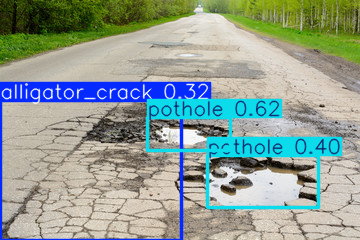

In [6]:
from ultralytics import YOLO
from IPython.display import display
from PIL import Image

# Load your trained model
model = YOLO("/kaggle/working/runs/alli_pothole/weights/best.pt")

# Change this to your new image path
image_path = "/kaggle/input/datasets/hailesintayehu/mmmmmmm"

# Run detection
results = model.predict(
    source=image_path,
    imgsz=960,
    conf=0.25,
    save=True
)

# Display detected image
result_image = results[0].plot()
display(Image.fromarray(result_image[..., ::-1]))

In [7]:
import shutil
shutil.copy("/kaggle/working/runs/alli_pothole/weights/best.pt",
            "/kaggle/working/alli_pothole_best.pt")

# check it works when loaded from the new file
from ultralytics import YOLO
model = YOLO("/kaggle/working/alli_pothole_best.pt")
print(model.names)   # should print {0: 'alligator_crack', 1: 'pothole'}

{0: 'alligator_crack', 1: 'pothole'}


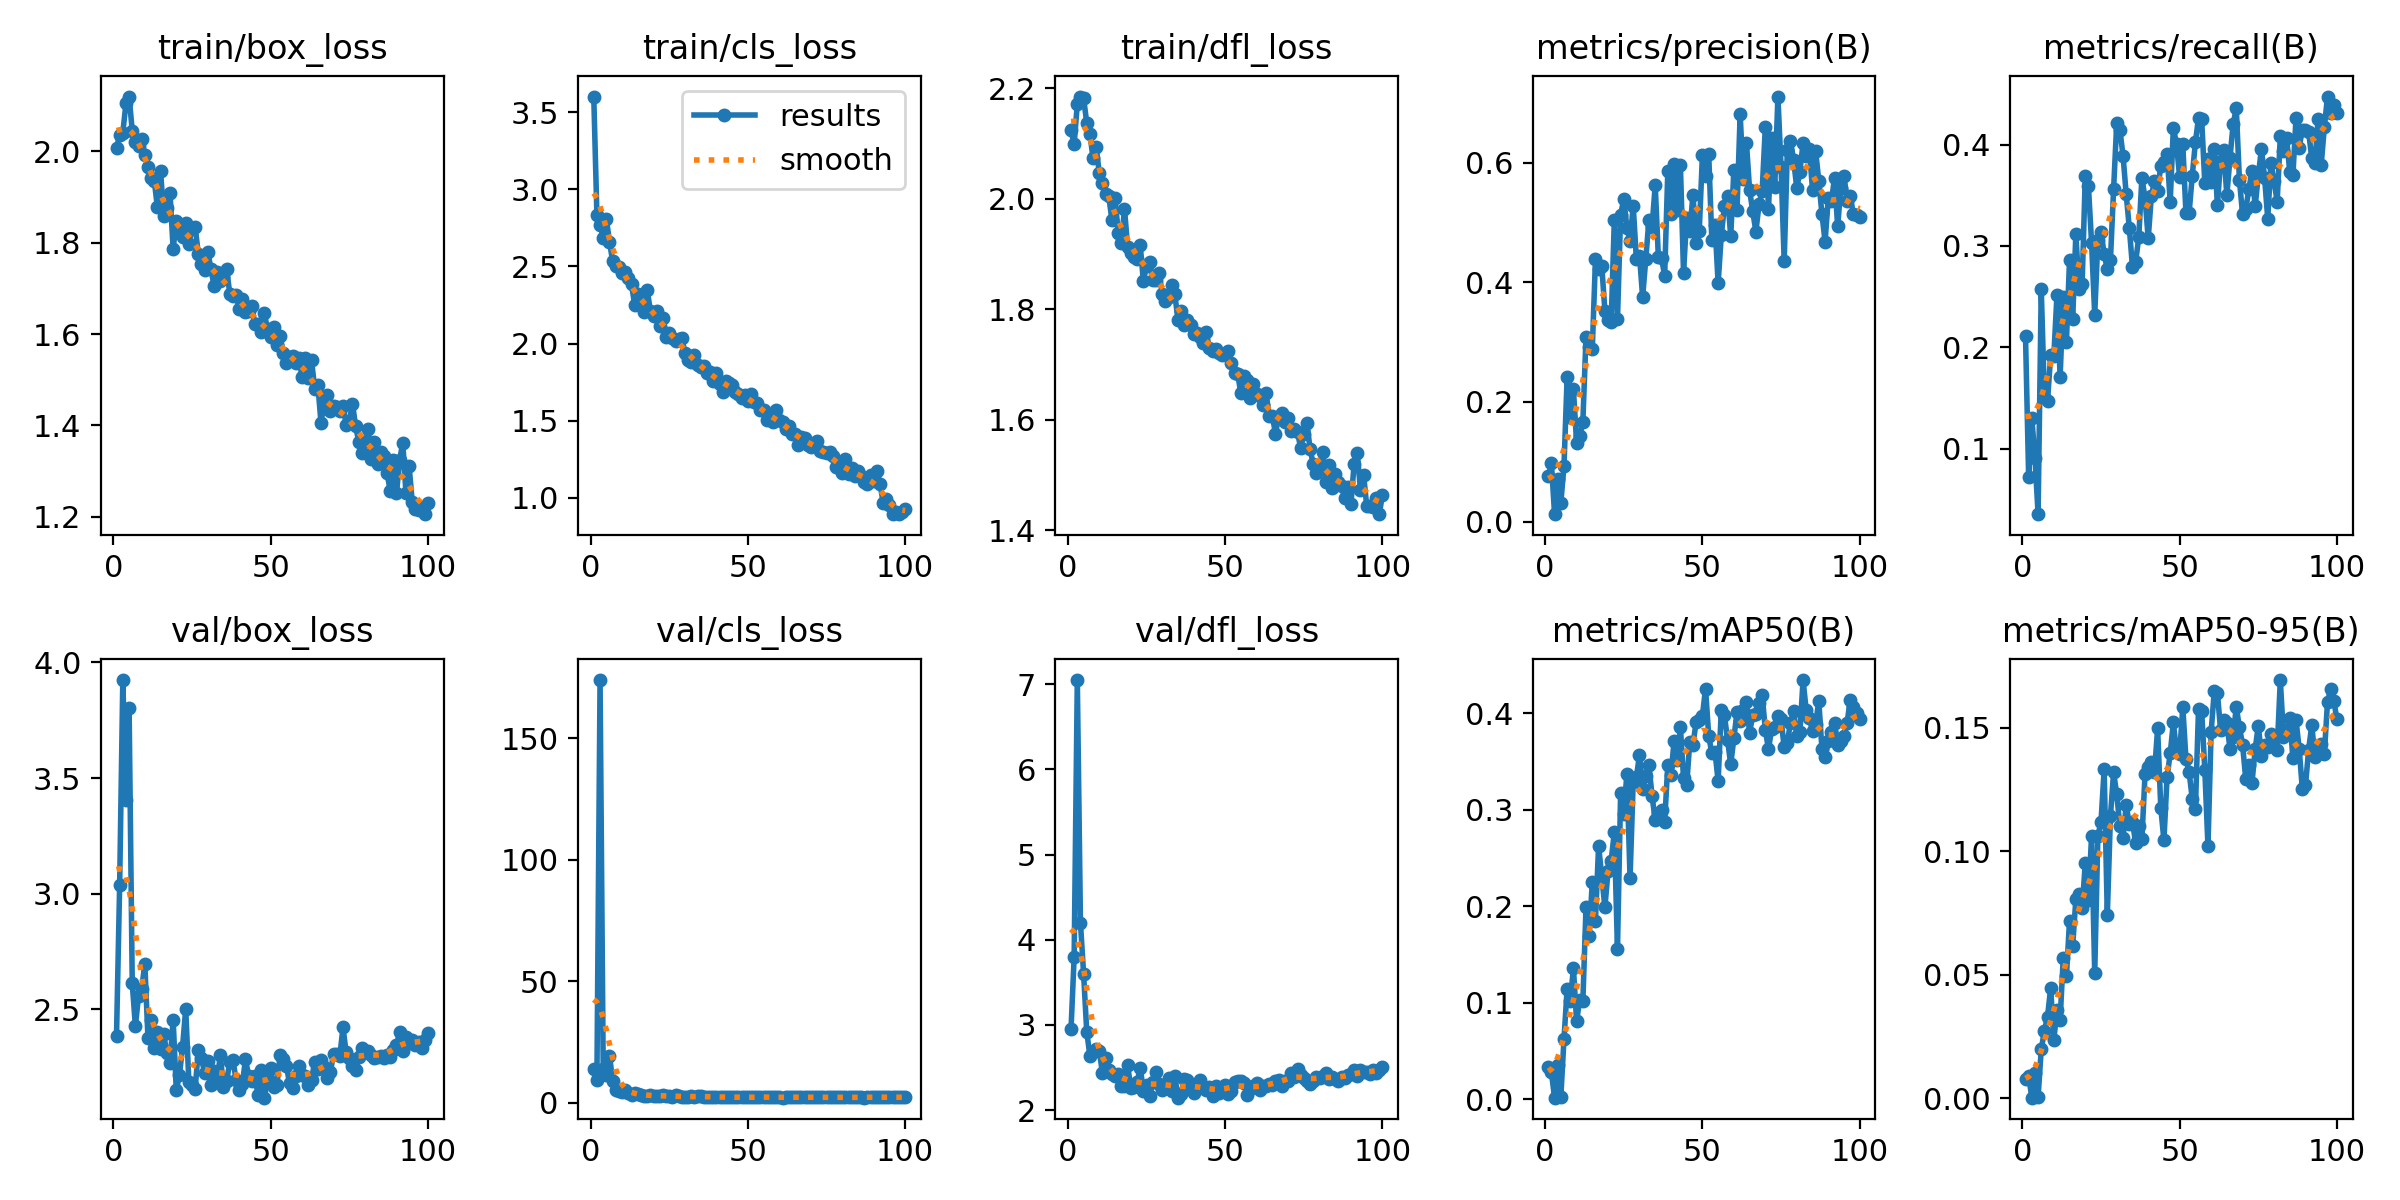

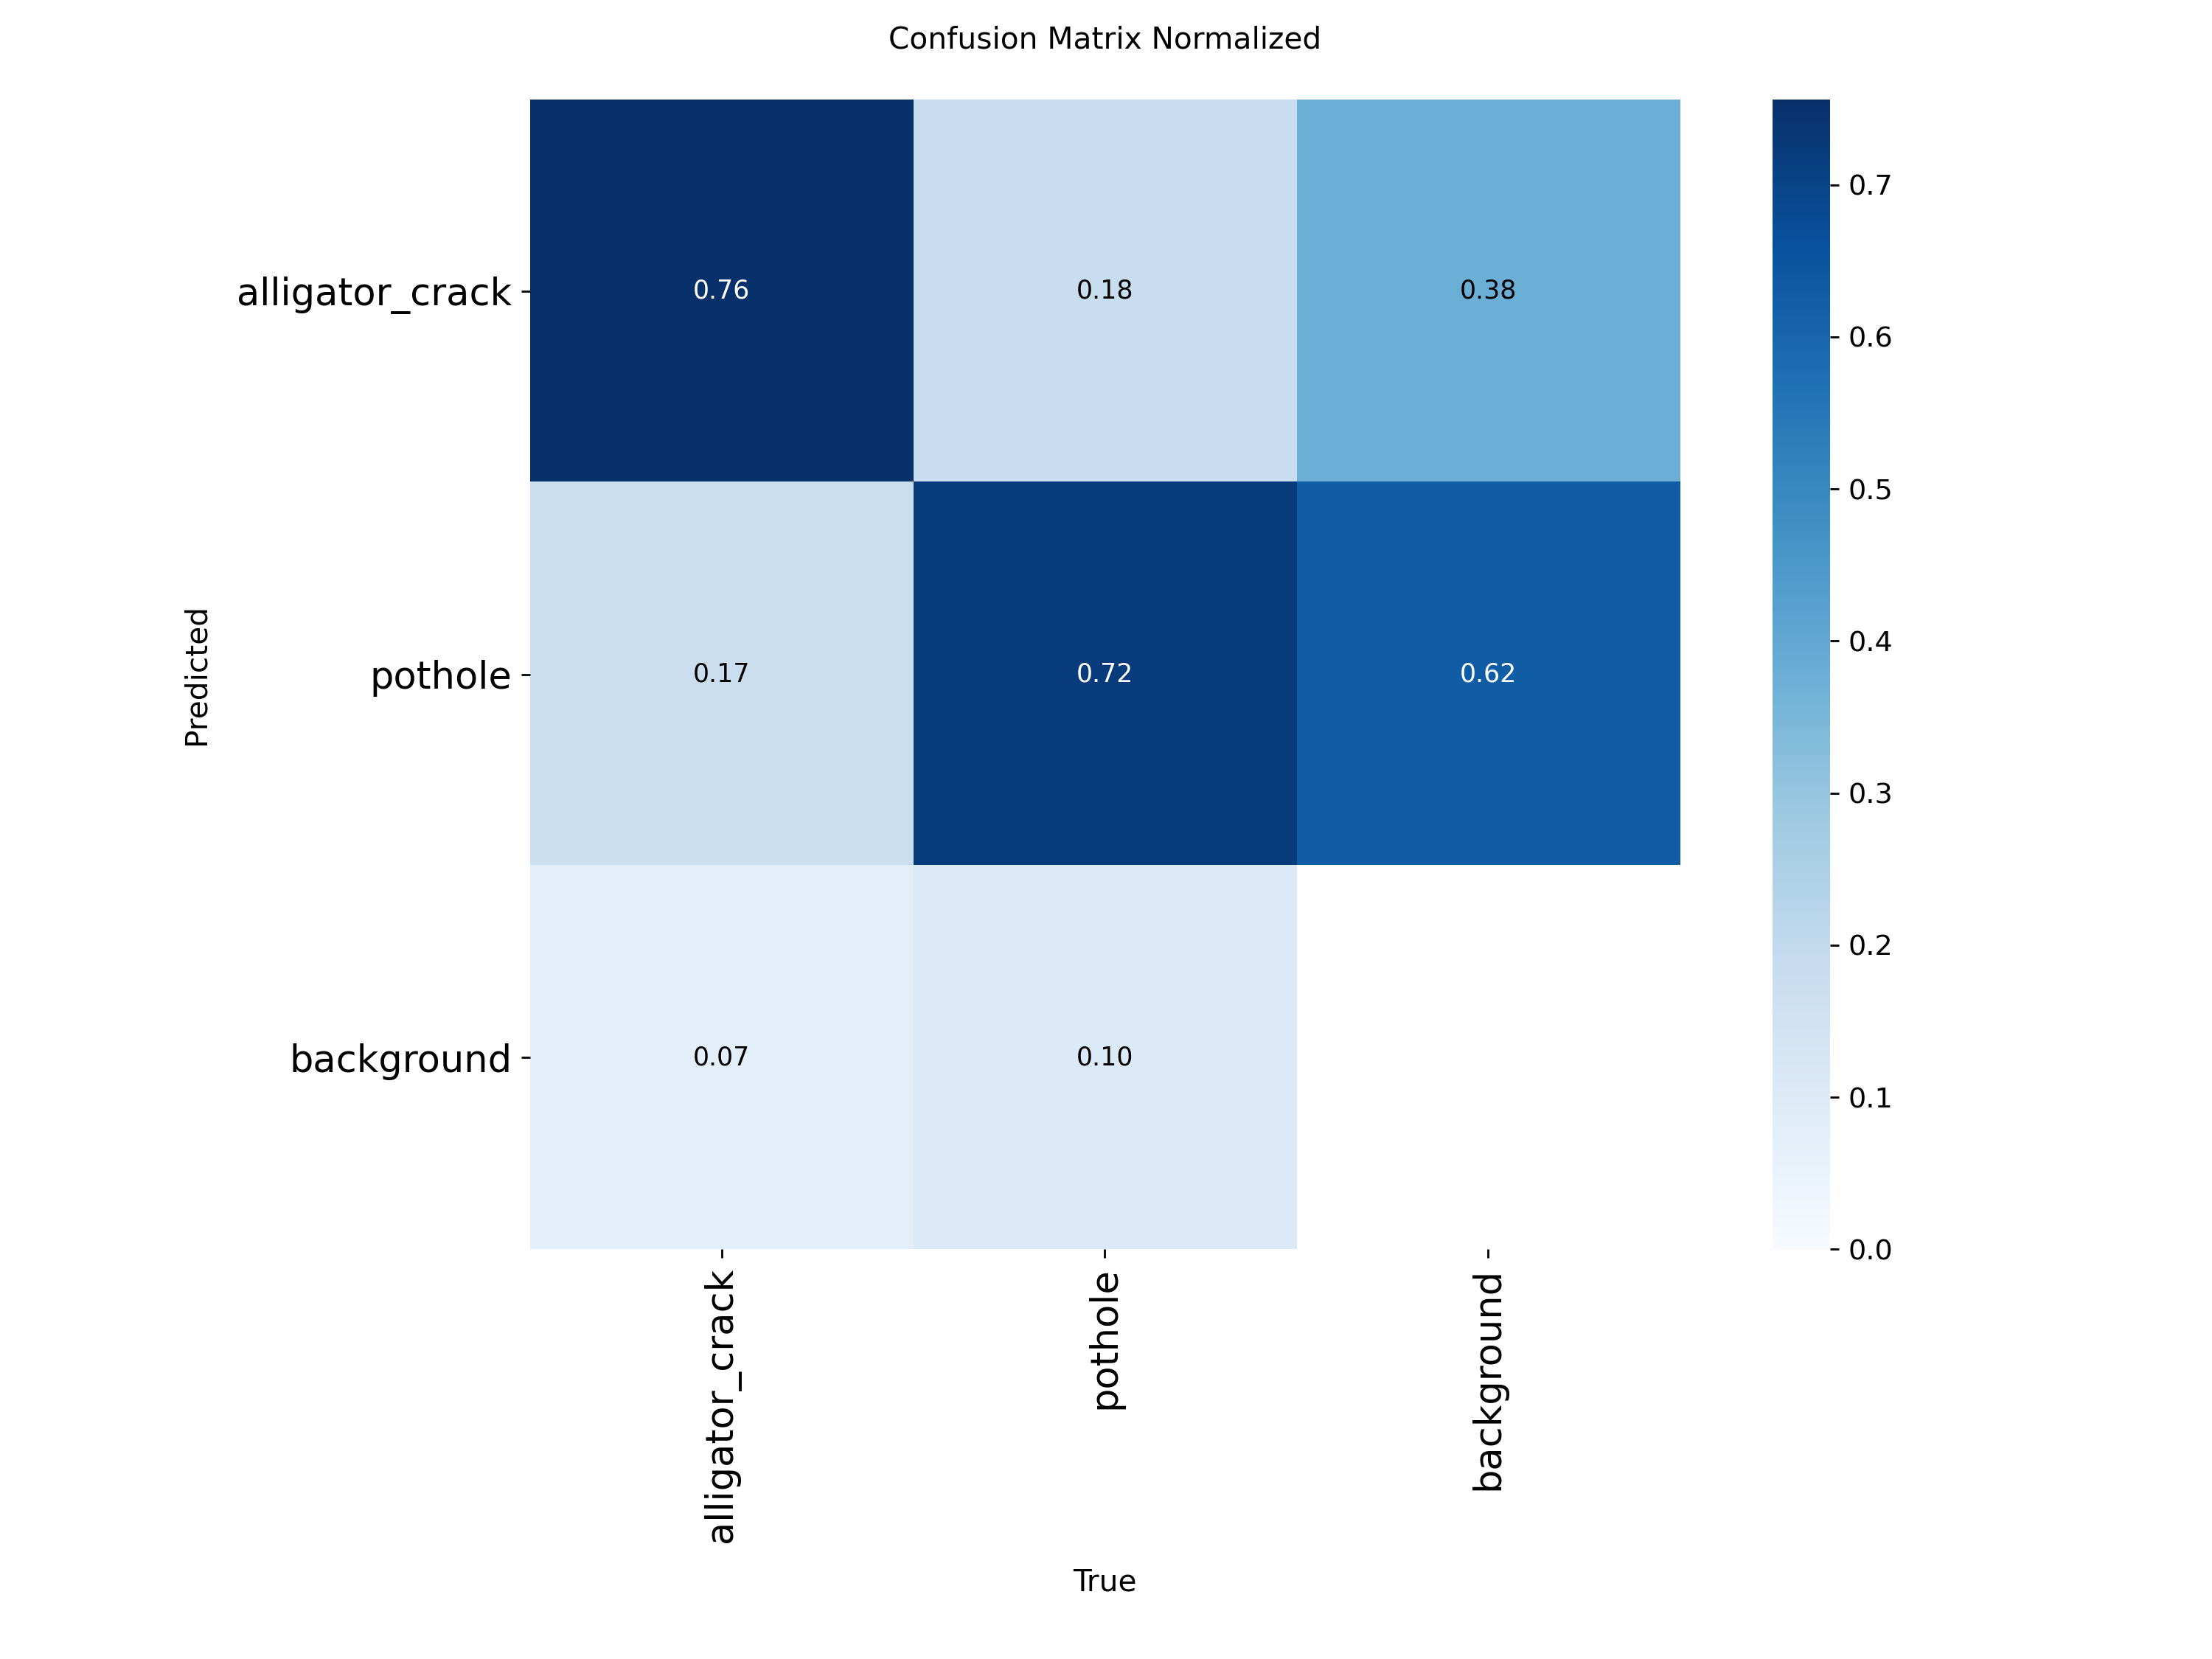

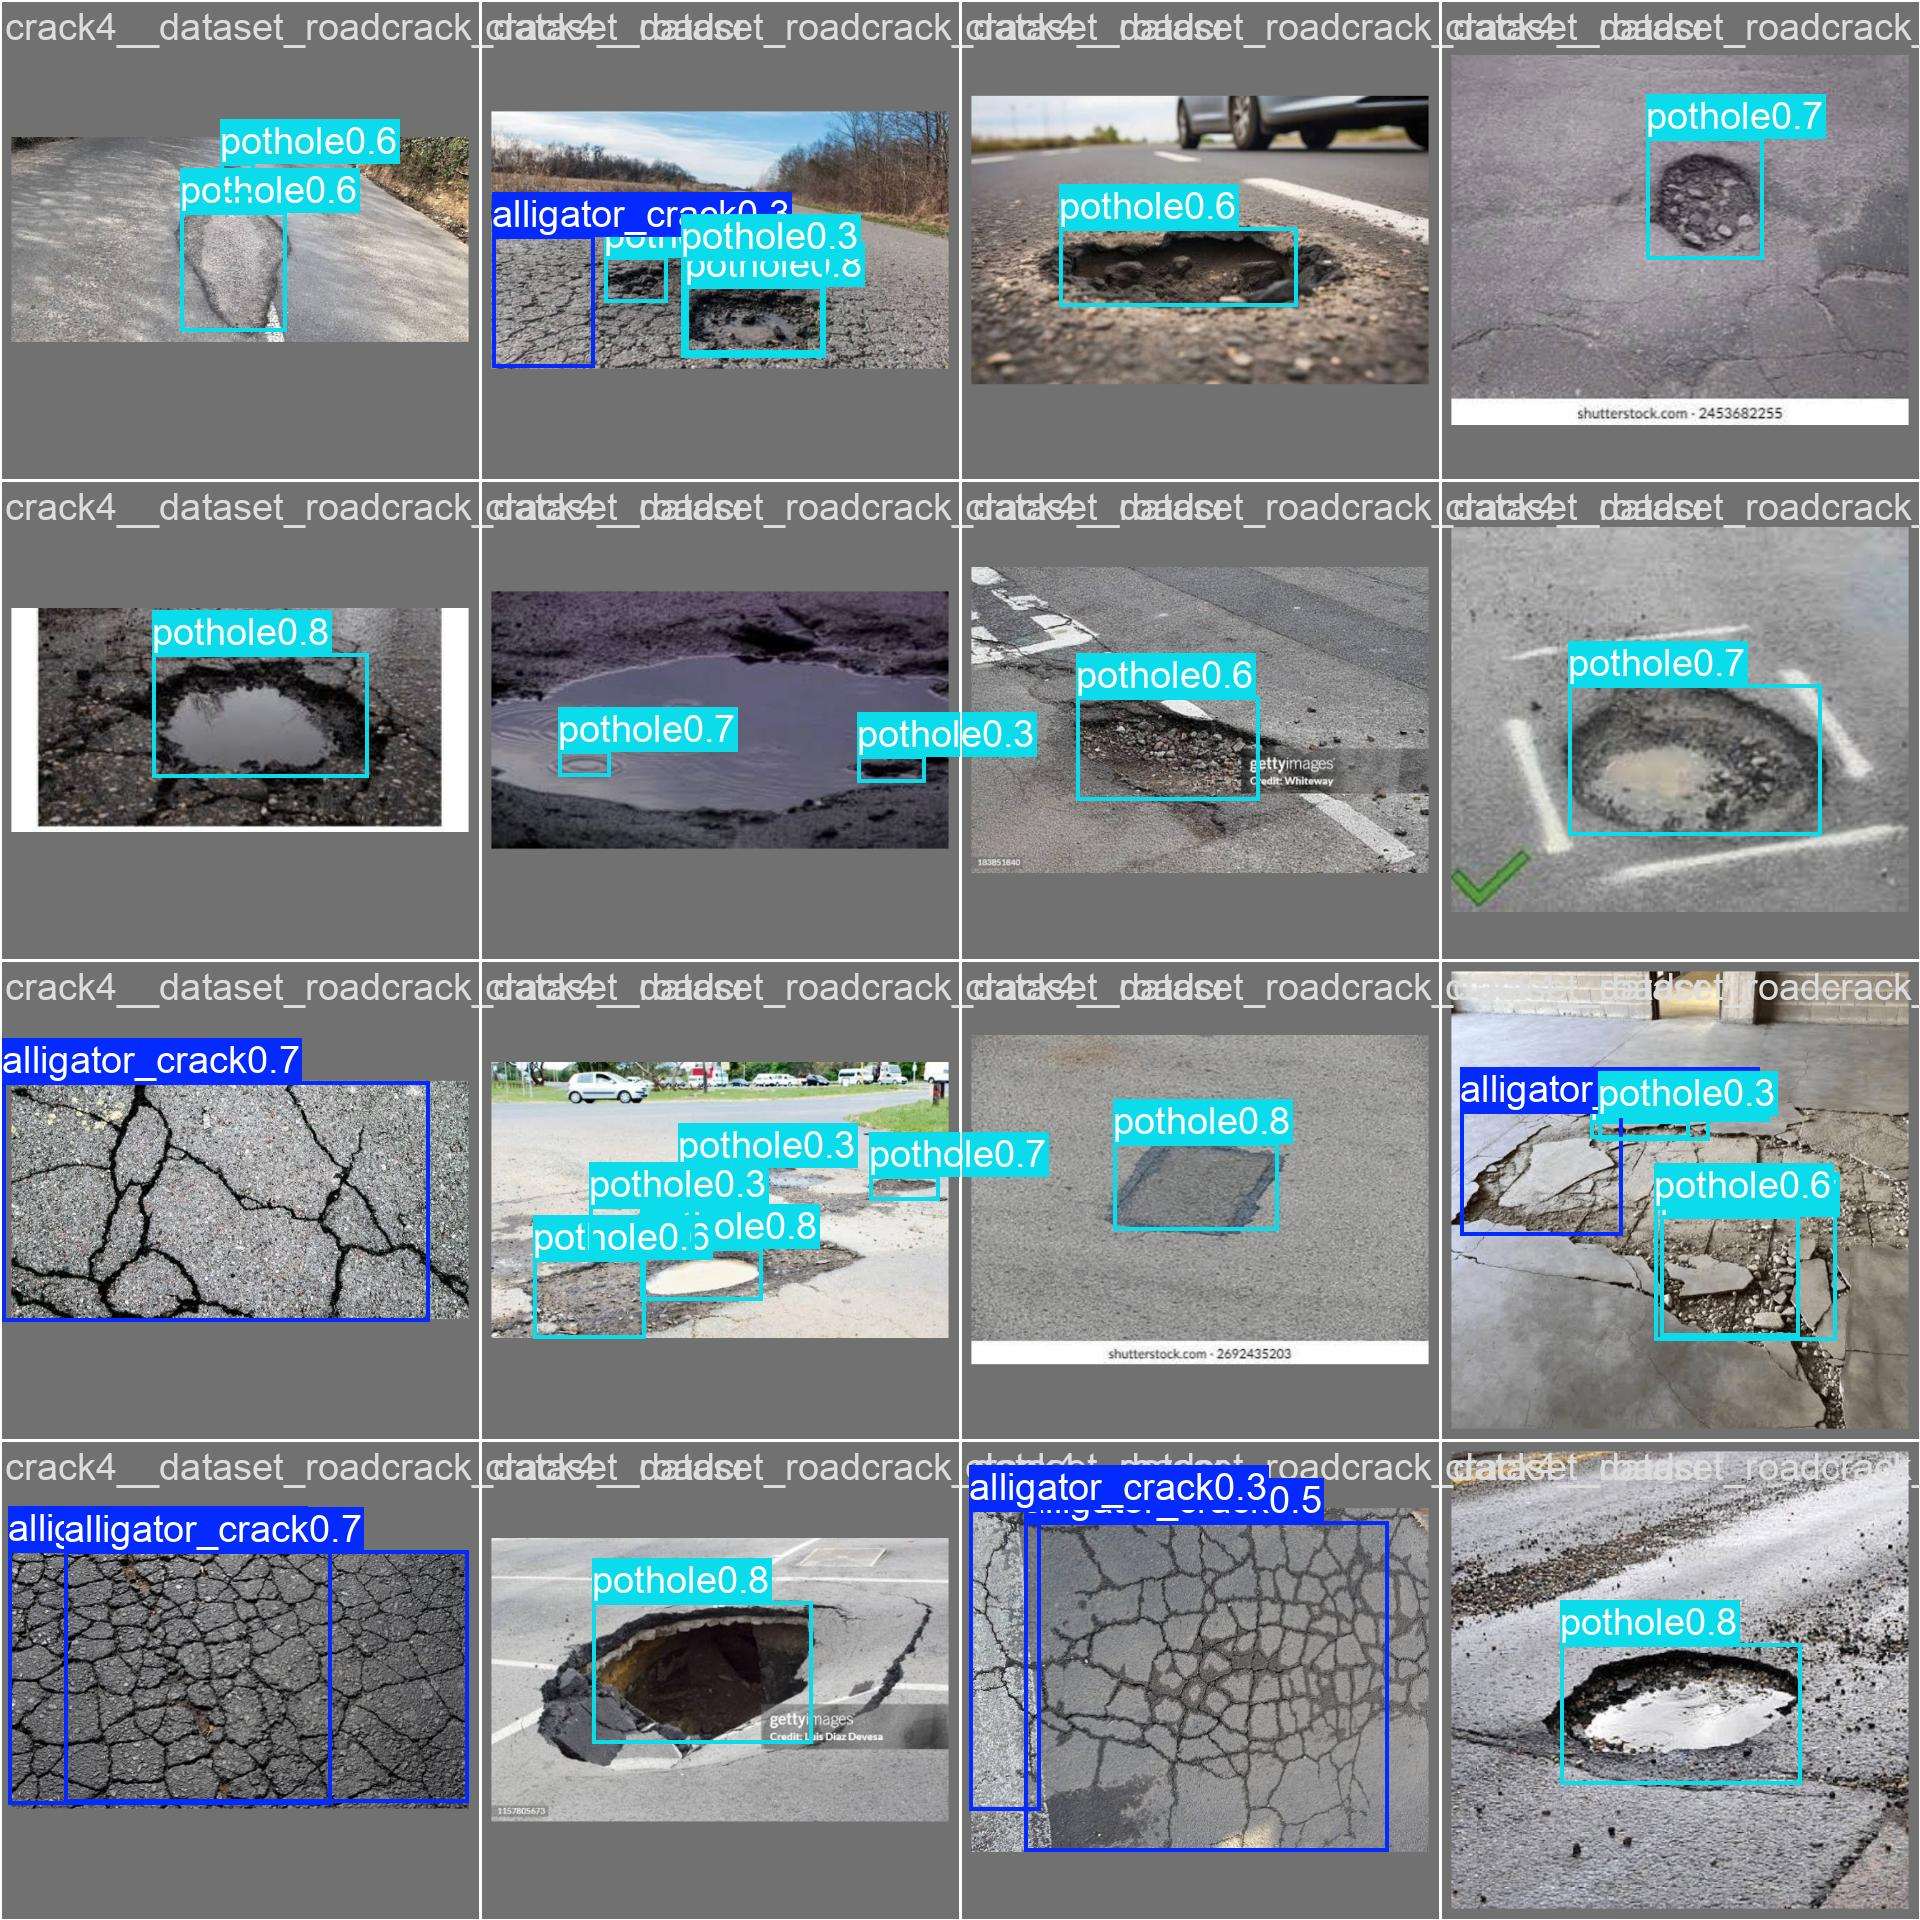

In [8]:
from IPython.display import Image, display
display(Image("/kaggle/working/runs/alli_pothole/results.png"))
display(Image("/kaggle/working/runs/alli_pothole/confusion_matrix_normalized.png"))
display(Image("/kaggle/working/runs/alli_pothole/val_batch0_pred.jpg"))